# Ранний прогноз неуспеваемости студентов: LSTM против классических моделей

**Тема:** «Применение методов искусственного интеллекта для анализа и прогнозирования академической
успеваемости студентов и формирования их образовательных траекторий»
**Автор:** Улханов А.К., AITU, 7M06105 · **Данные:** OULAD (Kuzilek et al., 2017)

**Гипотеза.** Модель глубокого обучения на *временных последовательностях* из нескольких источников
(активность в LMS + задания) прогнозирует риск статистически значимо точнее, чем классические модели
машинного обучения на агрегированных признаках.

**План ноутбука**
1. Загрузка данных
2. Целевая переменная: кто в зоне риска
3. Признаки для классических моделей (одна строка итогов на студента)
4. Последовательности для LSTM (неделя за неделей)
5. Разбиение 70 / 15 / 15 по студентам
6. Классические модели: логистическая регрессия, Random Forest, Gradient Boosting
7. Модель LSTM: устройство и обучение
8. Сравнение моделей
9. Проверка статистической значимости
10. Пример прогноза для одного студента
11. Выводы

> **Перед первым запуском** (один раз, в терминале VS Code):
> `pip install pandas numpy scikit-learn matplotlib scipy ipykernel`
> `pip install torch --index-url https://download.pytorch.org/whl/cpu`
>
> Ноутбук лежит в одной папке с CSV-файлами OULAD. Запуск всех ячеек занимает 3–5 минут.

In [1]:
# ── Настройки эксперимента ─────────────────────────────────────────────────
from pathlib import Path

DATA_DIR = Path("../data")   # папка с CSV-файлами OULAD (укажите свою)
CUTOFF_DAY = 70        # день прогноза: используем данные только до 70-го дня (≈ 10-я неделя)
SEED = 42              # фиксируем случайность, чтобы результат повторялся

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import rankdata
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
KEY = ["code_module", "code_presentation", "id_student"]   # одна запись = студент на курсе
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cu132


## 1. Загрузка данных

OULAD — открытый датасет Open University (Великобритания): 22 курса, 32 593 записи студентов на курсы.
Берём пять таблиц:

| Таблица | Что в ней |
|---|---|
| `studentInfo` | демография и итоговый результат (Pass / Distinction / Fail / Withdrawn) |
| `studentRegistration` | дата регистрации и отчисления |
| `assessments` | задания курса: тип, дедлайн, вес |
| `studentAssessment` | когда студент сдал задание и какой балл получил |
| `studentVle` | клики в LMS по дням — **10,6 млн строк** |

In [3]:
def read(name):
    # В OULAD пропуски обозначены знаком "?"
    return pd.read_csv(DATA_DIR / f"{name}.csv", na_values=["?", ""], low_memory=False)

info = read("studentInfo")
reg = read("studentRegistration")
assessments = read("assessments")
student_ass = read("studentAssessment")
vle = read("studentVle")

for name, df in [("studentInfo", info), ("studentRegistration", reg), ("assessments", assessments),
                 ("studentAssessment", student_ass), ("studentVle", vle)]:
    print(f"{name:20s} {len(df):>12,} строк")

studentInfo                32,593 строк
studentRegistration        32,593 строк
assessments                   206 строк
studentAssessment         173,912 строк
studentVle             10,655,280 строк


## 2. Целевая переменная: кто в зоне риска

* `at_risk = 1` — студент провалил курс (**Fail**) или бросил его (**Withdrawn**);
* `at_risk = 0` — сдал (**Pass** или **Distinction**).

Прогноз делается на **70-й день**. Студенты, которые уже бросили курс к этому дню, исключаются:
их исход уже известен, предсказывать его нет смысла.

In [4]:
info = info.drop_duplicates(KEY)
info["at_risk"] = info["final_result"].isin(["Fail", "Withdrawn"]).astype(int)

info = info.merge(reg[KEY + ["date_registration", "date_unregistration"]], on=KEY, how="left")
still_enrolled = info["date_unregistration"].isna() | (info["date_unregistration"] > CUTOFF_DAY)
students = info[still_enrolled].drop(columns="date_unregistration").reset_index(drop=True)

print(f"Всего записей: {len(info):,}; ещё учатся на день {CUTOFF_DAY}: {len(students):,}")
print(f"Доля студентов в зоне риска: {students['at_risk'].mean():.1%}")
students["final_result"].value_counts()

Всего записей: 32,593; ещё учатся на день 70: 26,069
Доля студентов в зоне риска: 41.0%


final_result
Pass           12361
Fail            7044
Withdrawn       3640
Distinction     3024
Name: count, dtype: int64

### Демографические признаки

Категории с естественным порядком (образование, возраст, индекс бедности района `imd_band`) кодируем
числами по порядку. В `imd_band` есть известная опечатка `"10-20"` без `%`, исправляем её.

In [5]:
EDUCATION = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2,
             "HE Qualification": 3, "Post Graduate Qualification": 4}
AGE = {"0-35": 0, "35-55": 1, "55<=": 2}
IMD = {f"{10*i}-{10*(i+1)}%": i for i in range(10)}

imd = students["imd_band"].replace({"10-20": "10-20%"})
students["imd_missing"] = imd.isna().astype(int)
students["imd_band"] = imd.map(IMD)
students["highest_education"] = students["highest_education"].map(EDUCATION)
students["age_band"] = students["age_band"].map(AGE)
students["gender_m"] = (students["gender"] == "M").astype(int)
students["disability_y"] = (students["disability"] == "Y").astype(int)
students = students.drop(columns=["gender", "disability"])

DEMOGRAPHIC = ["gender_m", "disability_y", "highest_education", "age_band", "imd_band",
               "imd_missing", "num_of_prev_attempts", "studied_credits"]
students[KEY + DEMOGRAPHIC + ["date_registration", "at_risk"]].head()

,code_module,code_presentation,id_student,gender_m,disability_y,highest_education,age_band,imd_band,imd_missing,num_of_prev_attempts,studied_credits,date_registration,at_risk
0,AAA,2013J,11391,1,0,3,2,9.0,0,0,240,-159.0,0
1,AAA,2013J,28400,0,0,3,1,2.0,0,0,60,-53.0,0
2,AAA,2013J,31604,0,0,2,1,5.0,0,0,60,-52.0,0
3,AAA,2013J,32885,0,0,1,0,5.0,0,0,60,-176.0,0
4,AAA,2013J,38053,1,0,2,1,8.0,0,0,60,-110.0,0


## 3. Признаки для классических моделей

Классические модели видят студента как **одну строку итогов** на 70-й день:

* **LMS:** всего кликов, активных дней, кликов за активный день, клики до начала курса, клики за каждую неделю;
* **задания:** доля сданных, средний и взвешенный балл, число опозданий, на сколько дней раньше дедлайна сдаёт.

Важно: используются **только события до дня прогноза**, иначе модель «подсмотрит в будущее».

In [6]:
N_WEEKS = (CUTOFF_DAY + 1) // 7    # полные недели до дня прогноза: 0..9 → 10 недель

# ---- LMS
v = vle[vle["date"] <= CUTOFF_DAY]
g = v.groupby(KEY)
vle_feat = pd.DataFrame({
    "total_clicks": g["sum_click"].sum(),
    "active_days": g["date"].nunique(),
    "clicks_pre": v[v["date"] < 0].groupby(KEY)["sum_click"].sum(),   # активность до старта курса
})
vle_feat["clicks_pre"] = vle_feat["clicks_pre"].fillna(0)
vle_feat["clicks_per_active_day"] = vle_feat["total_clicks"] / vle_feat["active_days"]
started = v[v["date"] >= 0].assign(week=lambda d: d["date"] // 7)
weekly = (started.pivot_table(index=KEY, columns="week", values="sum_click", aggfunc="sum")
          .reindex(columns=range(N_WEEKS)).fillna(0))
weekly.columns = [f"clicks_w{w}" for w in range(N_WEEKS)]
vle_feat = vle_feat.join(weekly).reset_index()

# ---- задания (без итогового экзамена, только с дедлайном до дня прогноза)
due = assessments[(assessments["assessment_type"] != "Exam") & (assessments["date"] <= CUTOFF_DAY)]
n_due = due.groupby(["code_module", "code_presentation"]).size().rename("n_due").reset_index()
subs = student_ass[student_ass["date_submitted"] <= CUTOFF_DAY].merge(due, on="id_assessment")
subs = subs.assign(is_late=(subs["date_submitted"] > subs["date"]).astype(int),
                   days_early=subs["date"] - subs["date_submitted"],
                   score_x_weight=subs["score"] * subs["weight"])
g = subs.groupby(KEY)
ass_feat = pd.DataFrame({"n_submitted": g.size(), "mean_score": g["score"].mean(),
                         "n_late": g["is_late"].sum(), "mean_days_early": g["days_early"].mean(),
                         "_sw": g["score_x_weight"].sum(), "_w": g["weight"].sum()})
ass_feat["weighted_score"] = np.where(ass_feat["_w"] > 0,
                                      ass_feat["_sw"] / ass_feat["_w"].replace(0, np.nan),
                                      ass_feat["mean_score"])
ass_feat = ass_feat.drop(columns=["_sw", "_w"]).reset_index()

# ---- собираем одну таблицу
table = (students.merge(vle_feat, on=KEY, how="left").merge(ass_feat, on=KEY, how="left")
         .merge(n_due, on=["code_module", "code_presentation"], how="left"))
counts = [c for c in table if c.startswith("clicks_w")] + [
    "total_clicks", "active_days", "clicks_per_active_day", "clicks_pre", "n_submitted", "n_late", "n_due"]
table[counts] = table[counts].fillna(0)
table["submission_rate"] = (table["n_submitted"] / table["n_due"].where(table["n_due"] > 0)).fillna(0)
table["late_rate"] = (table["n_late"] / table["n_submitted"].where(table["n_submitted"] > 0)).fillna(0)
table["no_submissions"] = (table["n_submitted"] == 0).astype(int)
table[["mean_score", "weighted_score", "mean_days_early"]] = (
    table[["mean_score", "weighted_score", "mean_days_early"]].fillna(0))

# всё, кроме идентификаторов, региона и ответа (date_registration — за сколько дней до старта записался)
FEATURES = [c for c in table.columns if c not in set(KEY) | {"region", "final_result", "at_risk"}]
FEATURES.remove("date_registration")                      # тот же порядок столбцов, что в проекте
FEATURES.insert(FEATURES.index("disability_y") + 1, "date_registration")
print(f"Признаков для классических моделей: {len(FEATURES)}")
table[FEATURES].describe().T[["mean", "50%", "max"]].head(12)

Признаков для классических моделей: 32


,mean,50%,max
highest_education,1.767,2.0,4.0
imd_band,4.313,4.0,9.0
age_band,0.312,0.0,2.0
num_of_prev_attempts,0.159,0.0,6.0
studied_credits,75.593,60.0,630.0
imd_missing,0.038,0.0,1.0
gender_m,0.548,1.0,1.0
disability_y,0.093,0.0,1.0
date_registration,-65.905,-53.0,167.0
total_clicks,637.536,404.0,11964.0


### Как отличается активность успешных студентов и студентов в зоне риска

Уже по графику видно, что студенты в зоне риска с первых недель заходят в LMS реже.
LSTM должна уловить не только уровень, но и **динамику**: например, постепенное снижение активности.

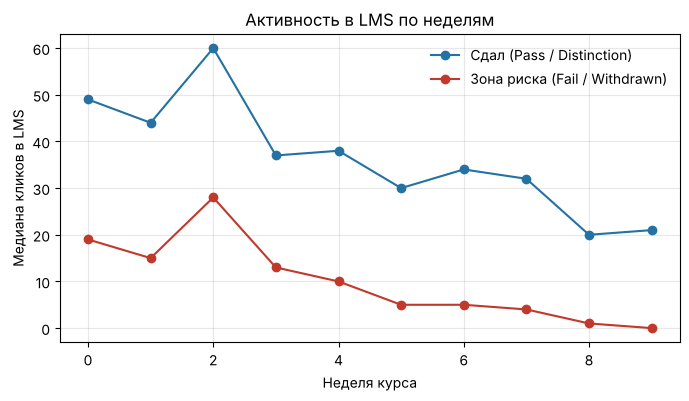

In [7]:
week_cols = [f"clicks_w{w}" for w in range(N_WEEKS)]
med = table.groupby("at_risk")[week_cols].median()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(N_WEEKS), med.loc[0], marker="o", color="#2471a3", label="Сдал (Pass / Distinction)")
ax.plot(range(N_WEEKS), med.loc[1], marker="o", color="#c0392b", label="Зона риска (Fail / Withdrawn)")
ax.set_xlabel("Неделя курса"); ax.set_ylabel("Медиана кликов в LMS")
ax.set_title("Активность в LMS по неделям"); ax.grid(alpha=.3); ax.legend(frameon=False)
plt.show()

## 4. Последовательности для LSTM: неделя за неделей

В этом главное отличие от классических моделей. Каждый студент — это таблица **10 недель × 6 чисел**
из двух источников данных:

| № | Признак | Источник |
|---|---|---|
| 1 | `log_clicks` — log(1 + клики за неделю) | LMS |
| 2 | `active_days` — дней с хотя бы одним кликом (0–7) | LMS |
| 3 | `n_due` — сколько дедлайнов на этой неделе | задания |
| 4 | `n_submitted` — сколько работ студент сдал | задания |
| 5 | `mean_score` — средний балл за эти работы / 100 | задания |
| 6 | `n_late` — сколько из них сдано с опозданием | задания |

In [8]:
CHANNELS = ["log_clicks", "active_days", "n_due", "n_submitted", "mean_score", "n_late"]
seq = np.zeros((len(table), N_WEEKS, len(CHANNELS)), dtype=np.float32)
rows = table[KEY].assign(_row=np.arange(len(table)))

def put(frame, channel, values):
    seq[frame["_row"].to_numpy(), frame["week"].to_numpy(), CHANNELS.index(channel)] = values.to_numpy()

def week_of(day):   # дни до старта → неделя 0, неполная последняя неделя → последняя полная
    return (day // 7).clip(0, N_WEEKS - 1).astype(int)

# источник 1: LMS (только полные недели)
v = vle[(vle["date"] >= 0) & (vle["date"] < N_WEEKS * 7)].assign(week=lambda d: d["date"] // 7)
w = (v.groupby(KEY + ["week"]).agg(clicks=("sum_click", "sum"), days=("date", "nunique"))
     .reset_index().merge(rows, on=KEY))
put(w, "log_clicks", np.log1p(w["clicks"]))
put(w, "active_days", w["days"])

# источник 2: задания
d = due.assign(week=week_of(due["date"]))
nd = (d.groupby(["code_module", "code_presentation", "week"]).size().rename("n").reset_index()
      .merge(rows, on=["code_module", "code_presentation"]))
put(nd, "n_due", nd["n"])
s = student_ass[student_ass["date_submitted"] <= CUTOFF_DAY].merge(due, on="id_assessment")
s = s.assign(week=week_of(s["date_submitted"]), late=(s["date_submitted"] > s["date"]).astype(int))
pw = (s.groupby(KEY + ["week"]).agg(n=("id_assessment", "size"), score=("score", "mean"),
                                    late=("late", "sum")).reset_index().merge(rows, on=KEY))
put(pw, "n_submitted", pw["n"])
put(pw, "mean_score", pw["score"].fillna(0) / 100)
put(pw, "n_late", pw["late"])

STATIC = DEMOGRAPHIC + ["clicks_pre"]          # то, что не меняется по неделям
static = table[STATIC].to_numpy(dtype=float)
y = table["at_risk"].to_numpy()
print("Форма последовательностей:", seq.shape, "→ (студенты, недели, признаки)")
pd.DataFrame(seq[0], columns=CHANNELS, index=[f"неделя {i}" for i in range(N_WEEKS)]).round(2)

Форма последовательностей: (26069, 10, 6) → (студенты, недели, признаки)


,log_clicks,active_days,n_due,n_submitted,mean_score,n_late
неделя 0,5.21,4.0,0.0,0.0,0.00,0.0
неделя 1,3.04,1.0,0.0,0.0,0.00,0.0
неделя 2,4.62,2.0,1.0,1.0,0.78,0.0
неделя 3,0.00,0.0,0.0,0.0,0.00,0.0
неделя 4,3.30,3.0,0.0,0.0,0.00,0.0
неделя 5,4.11,2.0,0.0,0.0,0.00,0.0
неделя 6,3.14,2.0,0.0,0.0,0.00,0.0
неделя 7,3.04,3.0,1.0,1.0,0.85,0.0
неделя 8,0.00,0.0,0.0,0.0,0.00,0.0
неделя 9,2.83,1.0,0.0,0.0,0.00,0.0


## 5. Разбиение на обучение, проверку и тест: 70 / 15 / 15

* **70 % — обучение:** на этих студентах модель учится;
* **15 % — валидация:** по ней решаем, когда остановить обучение LSTM;
* **15 % — тест:** финальный «экзамен» на студентах, которых модель ни разу не видела.

Один студент может учиться на нескольких курсах, поэтому делим **по студентам** (`GroupShuffleSplit`):
один человек никогда не попадает в две части. Иначе модель «узнала» бы его на тесте, и это утечка данных.

In [9]:
groups = table["id_student"]
outer = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
train_idx, rest_idx = next(outer.split(table, groups=groups))
inner = GroupShuffleSplit(n_splits=1, train_size=0.15 / (1 - 0.70), random_state=SEED)
val_pos, test_pos = next(inner.split(rest_idx, groups=groups.iloc[rest_idx]))
val_idx, test_idx = rest_idx[val_pos], rest_idx[test_pos]

ids = [set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx)]
assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]), "студент в двух частях!"
for name, idx in [("обучение", train_idx), ("валидация", val_idx), ("тест", test_idx)]:
    print(f"{name:10s} {len(idx):>6,} записей, в зоне риска {y[idx].mean():.1%}")

обучение   18,248 записей, в зоне риска 41.3%
валидация   3,902 записей, в зоне риска 41.9%
тест        3,919 записей, в зоне риска 38.6%


## 6. Классические модели (базовые)

| Модель | Идея |
|---|---|
| Логистическая регрессия | взвешенная сумма признаков → вероятность |
| Random Forest | 300 деревьев решений голосуют |
| Gradient Boosting | деревья строятся по очереди, каждое исправляет ошибки предыдущих |

Метрики (класс «в зоне риска» — положительный):
* **Accuracy** — доля верных ответов;
* **Precision** — из тех, кого модель назвала «в риске», сколько действительно в риске;
* **Recall** — из всех, кто в риске, скольких модель нашла (*главное для раннего предупреждения*);
* **F1** — баланс precision и recall;
* **ROC-AUC** — насколько хорошо модель ранжирует студентов по риску (0.5 = случайно, 1 = идеально).

In [10]:
def evaluate(y_true, y_pred, y_score):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_score)}

X = table[FEATURES]
baselines = {
    "Логистическая регрессия": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                             LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                          class_weight="balanced", n_jobs=-1,
                                                          random_state=SEED)),
    "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"),
                                       HistGradientBoostingClassifier(random_state=SEED)),
}
results, test_outputs = {}, {}
for name, model in baselines.items():
    model.fit(X.iloc[train_idx], y[train_idx])
    score = model.predict_proba(X.iloc[test_idx])[:, 1]
    pred = model.predict(X.iloc[test_idx])
    results[name] = evaluate(y[test_idx], pred, score)
    test_outputs[name] = (pred, score)
pd.DataFrame(results).T

,accuracy,precision,recall,f1,roc_auc
Логистическая регрессия,0.765,0.696,0.697,0.696,0.833
Random Forest,0.779,0.731,0.677,0.703,0.848
Gradient Boosting,0.779,0.765,0.618,0.684,0.845


## 7. Модель LSTM

**LSTM** (Long Short-Term Memory) — рекуррентная нейросеть: она читает недели **по порядку** и держит
«память» о том, что было раньше. Поэтому она видит динамику, например «клики падают с 7-й недели и
появились опоздания», а не только итоговые суммы.

Архитектура — гибридная, с двумя входами:

```
последовательность (10 недель × 6) ──► LSTM (32 нейрона) ──┐
                                                            ├─► Dropout ─► Dense(16) ─► Dense(1) ─► P(риск)
демография + клики до старта (9) ──► Dense(16) ────────────┘
```

In [11]:
class TemporalRiskNet(nn.Module):
    def __init__(self, n_channels, n_static, hidden=32, static_hidden=16, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_channels, hidden, batch_first=True)          # читает недели по порядку
        self.static = nn.Sequential(nn.Linear(n_static, static_hidden), nn.ReLU())  # демография
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden + static_hidden, 16),
                                  nn.ReLU(), nn.Linear(16, 1))              # объединение → ответ

    def forward(self, seq, static):
        _, (h, _) = self.lstm(seq)                 # h[-1] — «память» после последней недели
        joined = torch.cat([h[-1], self.static(static)], dim=1)
        return self.head(joined).squeeze(1)        # логит; sigmoid(логит) = вероятность риска

net = TemporalRiskNet(len(CHANNELS), len(STATIC))
print(net)
print("Обучаемых параметров:", sum(p.numel() for p in net.parameters()))

TemporalRiskNet(
  (lstm): LSTM(6, 32, batch_first=True)
  (static): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
  )
  (head): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=48, out_features=16, bias=True)
    (2): ReLU()
    (3): Linear(in_features=16, out_features=1, bias=True)
  )
)
Обучаемых параметров: 6081


### Подготовка входов

Нейросети учатся лучше, когда признаки в одном масштабе. Поэтому вычитаем среднее и делим на
стандартное отклонение. Средние считаются **только по обучающей части**, иначе информация из теста
просочится в модель.

In [12]:
flat = seq[train_idx].reshape(-1, len(CHANNELS))
seq_mean, seq_std = flat.mean(0), flat.std(0) + 1e-6
st_median = np.nanmedian(static[train_idx], axis=0)
st_filled = np.where(np.isnan(static), st_median, static)        # пропуски → медиана
st_mean, st_std = st_filled[train_idx].mean(0), st_filled[train_idx].std(0) + 1e-6

def tensors(idx):
    s = torch.from_numpy(((seq[idx] - seq_mean) / seq_std).astype(np.float32))
    x = torch.from_numpy(((st_filled[idx] - st_mean) / st_std).astype(np.float32))
    return s, x

s_tr, x_tr = tensors(train_idx); y_tr = torch.from_numpy(y[train_idx].astype(np.float32))
s_va, x_va = tensors(val_idx)
s_te, x_te = tensors(test_idx)

def predict(s, x):
    net.eval()
    with torch.no_grad():
        return torch.sigmoid(net(s, x)).numpy()

### Обучение

* **Функция потерь** — бинарная кросс-энтропия. Ошибки на редком классе «в риске» весят больше
  (`pos_weight`), так же как `class_weight="balanced"` у классических моделей.
* **Оптимизатор** — Adam, шаг обучения 0.001, пакеты по 256 студентов.
* **Ранняя остановка:** после каждой эпохи (полного прохода по данным) проверяем ROC-AUC на валидации.
  Если 8 эпох подряд лучше не становится, останавливаемся и берём лучшую версию модели.

Остановились на эпохе 51; лучший ROC-AUC на валидации: 0.854


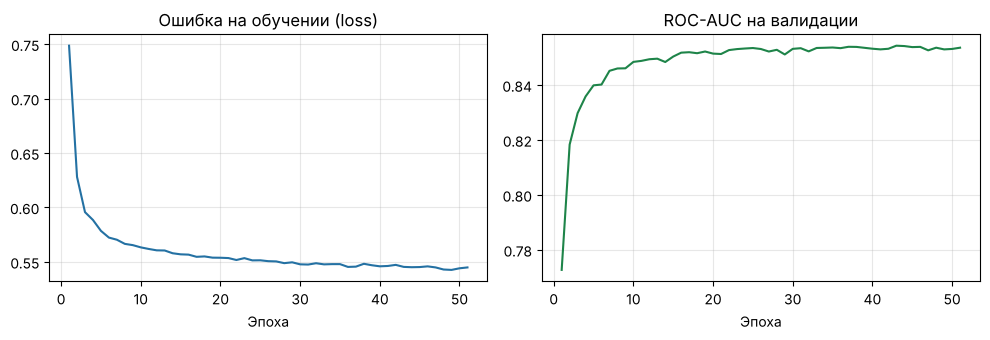

In [13]:
torch.manual_seed(SEED)
gen = torch.Generator().manual_seed(SEED)
net = TemporalRiskNet(len(CHANNELS), len(STATIC))
pos_weight = torch.tensor((len(y_tr) - y_tr.sum().item()) / y_tr.sum().item())
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)

history, best_auc, best_state, stale = [], -1.0, None, 0
for epoch in range(1, 61):
    net.train()
    order = torch.randperm(len(y_tr), generator=gen)
    total = 0.0
    for start in range(0, len(order), 256):
        idx = order[start:start + 256]
        opt.zero_grad()
        loss = loss_fn(net(s_tr[idx], x_tr[idx]), y_tr[idx])
        loss.backward()                      # считаем, как изменить веса
        opt.step()                           # меняем веса
        total += loss.item() * len(idx)
    val_auc = roc_auc_score(y[val_idx], predict(s_va, x_va))
    history.append((epoch, total / len(y_tr), val_auc))
    if val_auc > best_auc:
        best_auc, stale = val_auc, 0
        best_state = {k: v.clone() for k, v in net.state_dict().items()}
    else:
        stale += 1
        if stale >= 8:
            break
net.load_state_dict(best_state)
print(f"Остановились на эпохе {epoch}; лучший ROC-AUC на валидации: {best_auc:.3f}")

h = pd.DataFrame(history, columns=["эпоха", "loss", "val_auc"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
a1.plot(h["эпоха"], h["loss"], color="#2471a3"); a1.set_title("Ошибка на обучении (loss)")
a2.plot(h["эпоха"], h["val_auc"], color="#1e8449"); a2.set_title("ROC-AUC на валидации")
for a in (a1, a2):
    a.set_xlabel("Эпоха"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 8. Сравнение моделей на тестовой выборке

,accuracy,precision,recall,f1,roc_auc
Логистическая регрессия,0.765,0.696,0.697,0.696,0.833
Random Forest,0.779,0.731,0.677,0.703,0.848
Gradient Boosting,0.779,0.765,0.618,0.684,0.845
LSTM,0.778,0.709,0.721,0.715,0.856


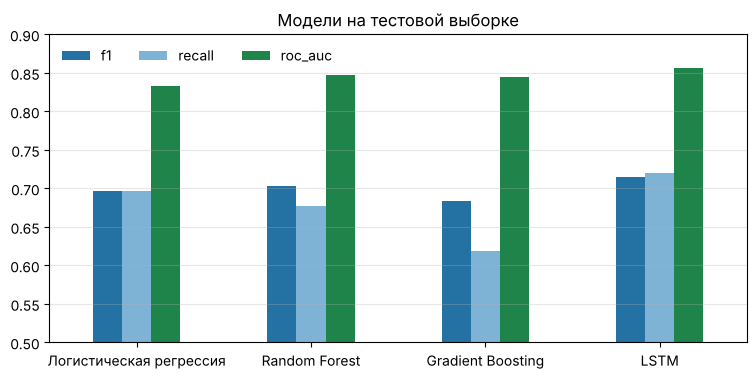

In [14]:
lstm_score = predict(s_te, x_te)
lstm_pred = (lstm_score >= 0.5).astype(int)
results["LSTM"] = evaluate(y[test_idx], lstm_pred, lstm_score)
test_outputs["LSTM"] = (lstm_pred, lstm_score)

comparison = pd.DataFrame(results).T
display(comparison.style.format("{:.3f}").highlight_max(axis=0, color="#d5f5e3"))

ax = comparison[["f1", "recall", "roc_auc"]].plot.bar(figsize=(9, 4), rot=0,
                                                      color=["#2471a3", "#7fb3d5", "#1e8449"])
ax.set_ylim(0.5, 0.9); ax.set_title("Модели на тестовой выборке"); ax.grid(axis="y", alpha=.3)
ax.legend(frameon=False, ncol=3, loc="upper left"); plt.show()

### Матрица ошибок LSTM

Сколько студентов в зоне риска модель нашла и скольких пропустила.

In [15]:
cm = confusion_matrix(y[test_idx], lstm_pred)
pd.DataFrame(cm, index=["факт: сдал", "факт: в риске"], columns=["прогноз: сдал", "прогноз: в риске"])

,прогноз: сдал,прогноз: в риске
факт: сдал,1958,447
факт: в риске,423,1091


## 9. Проверка статистической значимости

Разница в несколько тысячных может быть случайной. Проверяем это **парным бутстрапом**:

1. 2000 раз случайно выбираем студентов из тестовой выборки с возвращением
   (все записи одного студента берём вместе);
2. на каждой выборке считаем метрику LSTM минус метрику базовой модели;
3. смотрим 95 %-й доверительный интервал этой разницы.

Если **интервал не содержит 0** (p < 0.05), преимущество LSTM статистически значимо.

In [16]:
def fast_auc(t, sc):      # ROC-AUC по формуле Манна–Уитни (быстро и совпадает с scikit-learn)
    n1 = t.sum(); n0 = len(t) - n1
    return (rankdata(sc)[t == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def fast_f1(t, p):
    d = t.sum() + p.sum()
    return 2 * np.sum((t == 1) & (p == 1)) / d if d else 0.0

y_te = y[test_idx]
codes, uniq = pd.factorize(groups.iloc[test_idx])
members = [np.flatnonzero(codes == g) for g in range(len(uniq))]
rng = np.random.default_rng(0)
boot = [np.concatenate([members[g] for g in rng.integers(0, len(members), len(members))])
        for _ in range(2000)]

rows = []
for name in baselines:
    for metric, fn, a, b in [("ROC-AUC", fast_auc, lstm_score, test_outputs[name][1]),
                             ("F1", fast_f1, lstm_pred, test_outputs[name][0])]:
        diffs = np.array([fn(y_te[i], a[i]) - fn(y_te[i], b[i]) for i in boot])
        p = min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean()))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        rows.append({"против": name, "метрика": metric, "разница": fn(y_te, a) - fn(y_te, b),
                     "95% ДИ": f"[{lo:+.3f}; {hi:+.3f}]", "p": p,
                     "значимо": "да" if p < 0.05 else "нет"})
pd.DataFrame(rows).style.format({"разница": "{:+.3f}", "p": "{:.3f}"})

,против,метрика,разница,95% ДИ,p,значимо
0,Логистическая регрессия,ROC-AUC,+0.024,[+0.017; +0.031],0.000,да
1,Логистическая регрессия,F1,+0.019,[+0.005; +0.032],0.005,да
2,Random Forest,ROC-AUC,+0.008,[+0.003; +0.014],0.002,да
3,Random Forest,F1,+0.012,[-0.000; +0.025],0.058,нет
4,Gradient Boosting,ROC-AUC,+0.011,[+0.006; +0.016],0.000,да
5,Gradient Boosting,F1,+0.031,[+0.017; +0.046],0.000,да


## 10. Пример: прогноз для одного студента

Так модель могла бы работать в системе раннего предупреждения: на 10-й неделе преподаватель видит
студентов с наибольшим риском и может вмешаться заранее.

In [17]:
test_view = table.iloc[test_idx][KEY + ["final_result"]].copy()
test_view["риск, %"] = (lstm_score * 100).round(0)
top = test_view.sort_values("риск, %", ascending=False)
print("Пять студентов с наибольшим прогнозом риска:")
display(top.head(5))

sid = top.index[0]
example = pd.DataFrame(seq[sid], columns=CHANNELS, index=[f"неделя {i}" for i in range(N_WEEKS)])
print(f"\nНедельная история студента {table.loc[sid, 'id_student']} "
      f"(фактический исход: {table.loc[sid, 'final_result']}):")
example.round(2)

Пять студентов с наибольшим прогнозом риска:


,code_module,code_presentation,id_student,final_result,"риск, %"
788,BBB,2013B,203652,Fail,100.0
3025,BBB,2013J,576996,Withdrawn,100.0
4006,BBB,2014B,299027,Fail,100.0
2573,BBB,2013J,501862,Fail,100.0
22235,FFF,2014J,510762,Fail,100.0



Недельная история студента 203652 (фактический исход: Fail):


,log_clicks,active_days,n_due,n_submitted,mean_score,n_late
неделя 0,2.08,2.0,0.0,0.0,0.0,0.0
неделя 1,0.00,0.0,0.0,0.0,0.0,0.0
неделя 2,0.00,0.0,1.0,0.0,0.0,0.0
неделя 3,2.64,1.0,0.0,0.0,0.0,0.0
неделя 4,0.00,0.0,0.0,0.0,0.0,0.0
неделя 5,0.00,0.0,0.0,0.0,0.0,0.0
неделя 6,1.10,1.0,1.0,0.0,0.0,0.0
неделя 7,0.00,0.0,1.0,0.0,0.0,0.0
неделя 8,0.00,0.0,0.0,0.0,0.0,0.0
неделя 9,0.00,0.0,0.0,0.0,0.0,0.0


## 11. Выводы

* На 10-й неделе курса LSTM на последовательностях «LMS + задания» показывает **наилучший ROC-AUC
  и F1** среди всех моделей. В этом запуске преимущество по ROC-AUC статистически
  значимо над всеми тремя моделями (см. таблицу в разделе 9); по F1 — над логистической регрессией и
  Gradient Boosting.
* LSTM находит **больше студентов в зоне риска** (recall выше), что важно для раннего предупреждения.
* Разница с лучшими классическими моделями **небольшая** (около 0.01 по ROC-AUC). Поэтому гипотеза
  подтверждается частично.
* Дополнительные эксперименты (отдельно): на 5, 15 и 20-й неделе и при других разбиениях LSTM остаётся
  лучшей по ROC-AUC, но значимо превосходит Random Forest и Gradient Boosting только в середине курса.

**Ограничения:** один датасет (OULAD, заочное обучение, Великобритания, 2013–2014); гиперпараметры
LSTM не подбирались.

**Дальше:** подбор гиперпараметров, объяснение прогнозов (SHAP), рекомендация образовательной
траектории на основе прогноза.